This notebook simulates the cahnnel with sionna raytracing in NYCU

In [1]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!cd /content
!rm -rf EE_MIMO_PROJECT
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
%pip install -r requirements.txt
# change the dir
!ls
# just for checking that the current folder is correct

Cloning into 'EE_MIMO_PROJECT'...
remote: Enumerating objects: 285, done.
remote: Counting objects: 100% (285/285), done.
remote: Compressing objects: 100% (198/198), done.
remote: Total 285 (delta 110), reused 197 (delta 70), pack-reused 0 (from 0)
Receiving objects: 100% (285/285), 5.08 MiB | 9.86 MiB/s, done.
Resolving deltas: 100% (110/110), done.
/content/EE_MIMO_PROJECT
NYCU_scene  requirements.txt  simulation_results  src


In [2]:
# overall settings
ENV = dict(
    frequency = 28e9, #center frequency
    tx_position = [0, 0, 35],
    rx_position = [10, 10, 10],
)

PATHSOLVER_SETTING = dict(
    max_depth = 5,
    los = True, # include Line Of Site when when geometry permits it
    specular_reflection = True, # surface reflaction (true for multipath)
    diffuse_reflection = False, # rough-surface scattering
    refraction = True, # retains Sionna's material-dependent transmission/refraction model
    synthetic_array = False, # trace individual antenna positions (rather than the whole arry)
    samples_per_src = 1000000, # Ray/path-discovery sampling budget per source
    max_num_paths_per_src = 1000000, # Solver path-storage cap per source
    seed = 41
)

OFDM_SETTING = dict(
    num_avaliable_subcarriers = 4096,
    num_carrier_used = 1, # choose 16 subcarrier from total of 4096 subcarriers
    subcarrier_spacing = 30e3, # 30kHz spacing
)

TX_ARRY = dict(
    num_rows = 2,
    num_cols = 2,
    vertical_spacing = 0.5,
    horizontal_spacing = 0.5,
    pattern = "tr38901",
    polarization = "V"
)

RX_ARRY = dict(
    num_rows = 2,
    num_cols = 2,
    vertical_spacing = 0.5,
    horizontal_spacing = 0.5,
    pattern = "iso",
    polarization = "V"
)

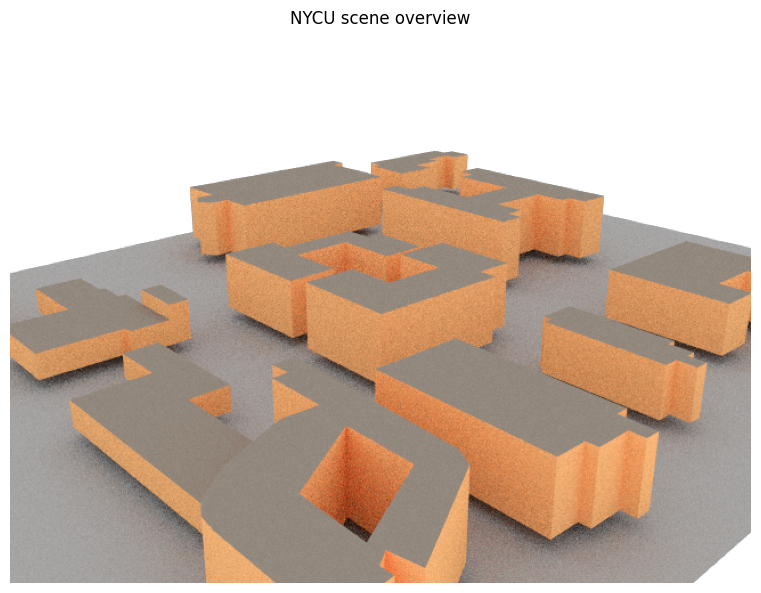

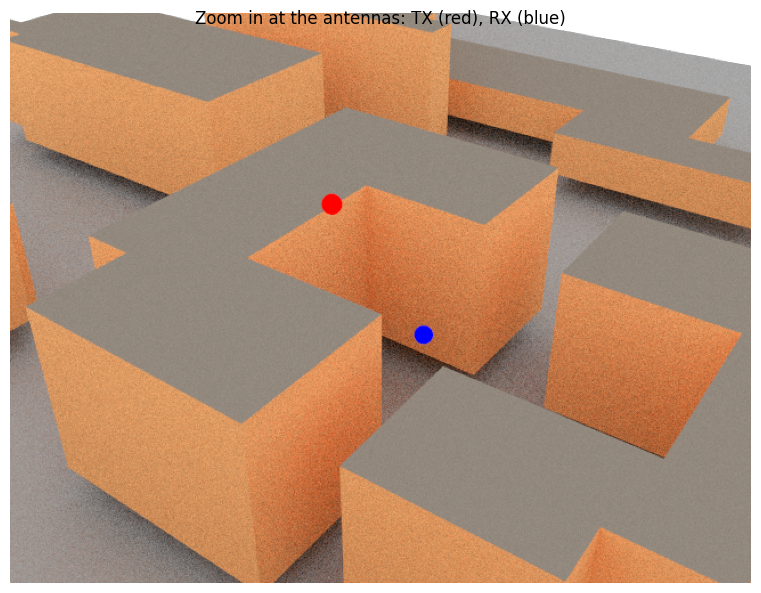

In [3]:
# environment and antenna
from sionna.rt import load_scene, Camera, PlanarArray, Transmitter, Receiver
from matplotlib import pyplot as plt

scene = load_scene("./NYCU_scene/NYCU.xml")
my_cam = Camera(position=[-250.1,250.1,150.1], look_at=[-15.001,30.1,28.1])
fig = scene.render(camera=my_cam, resolution=[650, 500], num_samples=32)
fig.suptitle("NYCU scene overview")
plt.show()

scene.frequency = ENV["frequency"]
scene.tx_array = PlanarArray(**TX_ARRY)
scene.rx_array = PlanarArray(**RX_ARRY)

tx = Transmitter(name="tx", position=ENV["tx_position"], display_radius=1.5, color=(1, 0, 0))
rx = Receiver(name="rx", position=ENV["rx_position"], display_radius=1.5, color=(0, 0, 1))
scene.add(tx)
scene.add(rx)
tx.look_at(rx)
my_cam_zoomin = Camera(position=[70, -90, 95], look_at=[5, 5, 18])
fig = scene.render(camera=my_cam_zoomin, resolution=[650, 500], num_samples=32)
fig.suptitle("Zoom in at the antennas: TX (red), RX (blue)")
plt.show()

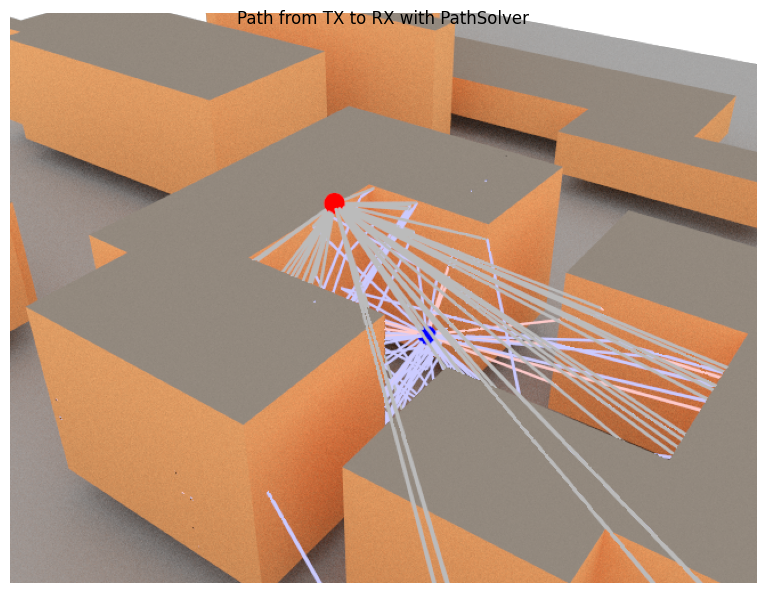

In [4]:
# path
from sionna.rt import PathSolver
paths = PathSolver()(scene=scene, **PATHSOLVER_SETTING)

fig = scene.render(camera=my_cam_zoomin, paths=paths, clip_at=35)
fig.suptitle("Path from TX to RX with PathSolver")
plt.show()

In [5]:
# channel base on carrier choosen
import numpy as np
indices = (np.array([OFDM_SETTING["num_avaliable_subcarriers"] // 2])
           if OFDM_SETTING["num_carrier_used"] == 1 else
           np.linspace(0, OFDM_SETTING["num_avaliable_subcarriers"] - 1, OFDM_SETTING["num_carrier_used"], dtype=int))
frequencies = (indices - OFDM_SETTING["num_avaliable_subcarriers"] // 2) * OFDM_SETTING["subcarrier_spacing"]
response = paths.cfr(frequencies=frequencies.astype(np.float32), normalize=False,
                     normalize_delays=True, out_type="numpy")
raw = np.asarray(response)[0, :, 0, :, 0, :].transpose(2, 0, 1)
power = float(np.mean(np.abs(raw)**2))
channel = raw / np.sqrt(power)
print(channel.shape)


(1, 4, 4)


In [ ]:
# Detection testbench
import torch
from src.channel.testbench import Testbench
from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": partialMAP(verbose=False),
}
symbols = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
bit_labels = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])
SYMBOLS_PER_CHANNEL = 1_000
SNR_DB = list(range(0, 22, 2))

# channel has shape (subcarriers, nr, nt).
bench = Testbench(models, symbols, bit_labels, SYMBOLS_PER_CHANNEL, SNR_DB)
ber, bits_per_snr = bench.run(channel, generator=torch.Generator().manual_seed(41))
print(f"{bits_per_snr:,} bits per SNR across {channel.shape[0]} subcarrier(s)")

8,000 bits per SNR across 1 subcarrier(s)


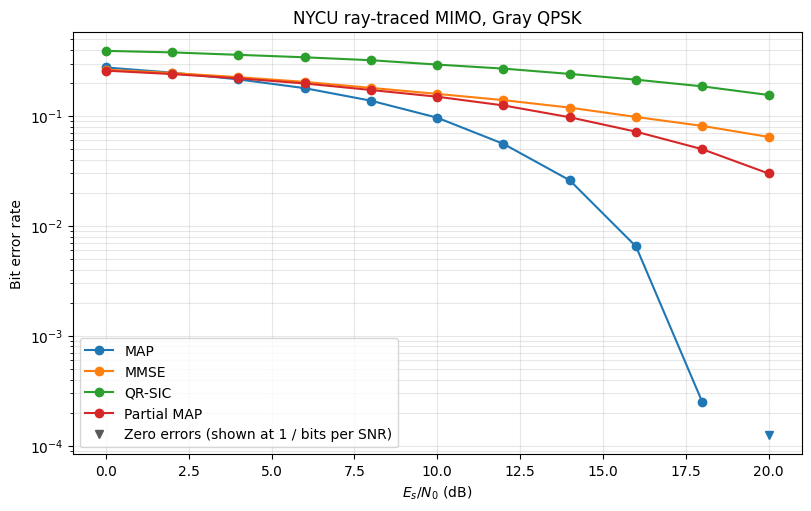

In [7]:
# Plot BER versus SNR
import matplotlib.pyplot as plt
import numpy as np

snr_db = np.asarray(SNR_DB)
ber_values = ber.cpu().numpy()
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")

for name, points in zip(models, ber_values.T):
    zero = points == 0
    line, = ax.semilogy(snr_db, np.where(zero, np.nan, points), "o-", label=name)
    if zero.any():
        ax.semilogy(snr_db[zero], np.full(zero.sum(), 1 / bits_per_snr),
                    "v", color=line.get_color())

if (ber_values == 0).any():
    ax.plot([], [], "v", color="0.35", label="Zero errors (shown at 1 / bits per SNR)")
ax.set(xlabel=r"$E_s/N_0$ (dB)", ylabel="Bit error rate",
       title="NYCU ray-traced MIMO, Gray QPSK")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

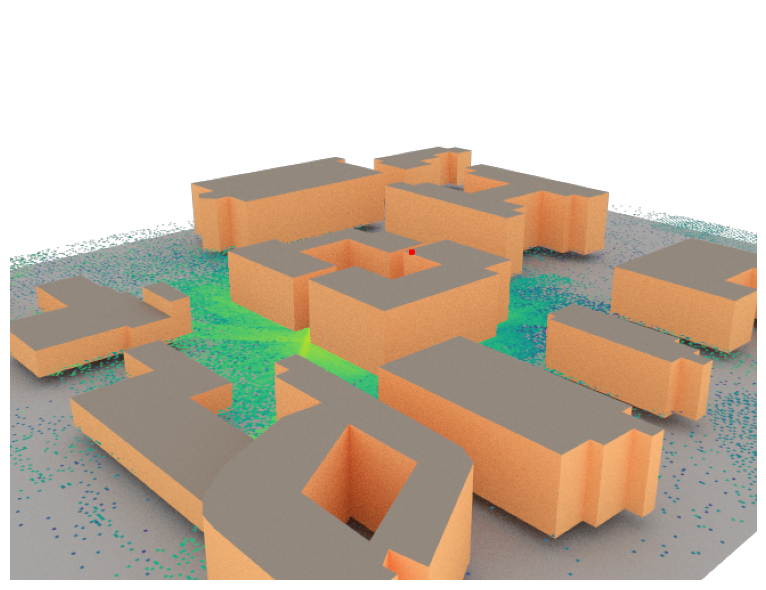

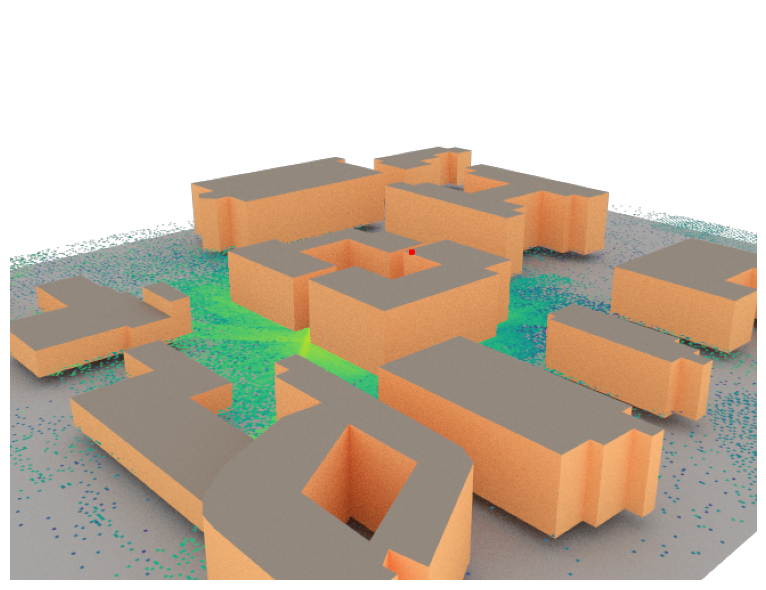

In [8]:
# just for fun, radiomap
from sionna.rt import RadioMapSolver
rm_solver = RadioMapSolver()

rm = rm_solver(scene=scene,
               max_depth=5,
               cell_size=[1,1],
               samples_per_tx=10**6)

scene.render(camera=my_cam, radio_map=rm)